In [5]:
import zipfile
import tensorflow as tf
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from tensorflow.keras import mixed_precision
zip_path = "/content/Cotton__Disease.zip"   # uploaded file
extract_path = "/content/dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted!")


Dataset extracted!


In [6]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Dense, Flatten, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.applications.resnet50 import ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import os
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input

# Define paths
train_path = "/content/dataset/Cotton Disease/train"
test_path = "/content/dataset/Cotton Disease/test"
val_path =  "/content/dataset/Cotton Disease/val"

# Image parameters
IMAGE_SIZE = [224, 224]
BATCH_SIZE = 32

# Data Augmentation needed for Training
# CRITICAL FIX: Use preprocess_input instead of rescale=1./255
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    rotation_range=20  # Added rotation for better augmentation
)

# Validation/Test should also use preprocess_input
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

# Training Set
train_set = train_datagen.flow_from_directory(
    train_path,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

# Validation Set
val_set = test_datagen.flow_from_directory(
    val_path,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

# Test Set
test_set = test_datagen.flow_from_directory(
    test_path,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)


Found 1951 images belonging to 4 classes.
Found 253 images belonging to 4 classes.
Found 106 images belonging to 4 classes.


In [7]:
# Load VGG16
base_model = VGG16(input_shape=IMAGE_SIZE + [3], weights='imagenet', include_top=False)

# Don't train existing weights initially
base_model.trainable = False

x = GlobalAveragePooling2D()(base_model.output)
# Simplified Head: 256 units
x = Dense(256, activation='relu')(x)
# Optimized Dropout (0.3)
x = Dropout(0.3)(x)
# Must use float32 for output layer when using mixed_precision
prediction = Dense(4, activation='softmax', dtype='float32')(x)

# Create Model
model = Model(inputs=base_model.input, outputs=prediction)

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()



58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,044 (56.64 MB)

 Trainable params: 132,356 (517.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [9]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint('model_vgg.h5', monitor='val_accuracy', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
]

# Train Phase 1: Feature Extraction (Head only)
print("Phase 1: Training Classification Head...")
history_1 = model.fit(
    train_set,
    validation_data=val_set,
    epochs=5, # OPTIMIZATION: Reduced from 10 to speed up
    steps_per_epoch=len(train_set),
    validation_steps=len(val_set),
    callbacks=callbacks
)

Phase 1: Training Classification Head...


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 20s/step - accuracy: 0.5655 - loss: 1.9072 
Epoch 1: val_accuracy improved from -inf to 0.90909, saving model to model_vgg.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 1349s 22s/step - accuracy: 0.5674 - loss: 1.8948 - val_accuracy: 0.9091 - val_loss: 0.2942 - learning_rate: 0.0010
Epoch 2/5
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 20s/step - accuracy: 0.8618 - loss: 0.4176 
Epoch 2: val_accuracy did not improve from 0.90909
61/61 ━━━━━━━━━━━━━━━━━━━━ 1346s 22s/step - accuracy: 0.8617 - loss: 0.4173 - val_accuracy: 0.9012 - val_loss: 0.2709 - learning_rate: 0.0010
Epoch 3/5
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 19s/step - accuracy: 0.8864 - loss: 0.2995 
Epoch 3: val_accuracy improved from 0.90909 to 0.92095, saving model to model_vgg.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 1438s 23s/step - accuracy: 0.8864 - loss: 0.2994 - val_accuracy: 0.9209 - val_loss: 0.2076 - learning_rate: 0.0010
Epoch 4/5
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 19s/step - accuracy: 0.9067 - loss: 0.2447 
Epoch 4: val_accuracy did not improve from 0.92095
61/61 ━━━━━━━━━━━━━━━━━━━━ 1328s 22s/step - accuracy: 0.9068 - loss: 0.2447 - val_accuracy: 0.9209 - val_loss: 0.1898 - learning_rate: 0.0010
Epoch 5/5
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 19s/step - accuracy: 0.9285 - loss: 0.2155 
Epoch 5: val_accuracy improved from 0.92095 to 0.92490, saving model to model_vgg.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 1325s 22s/step - accuracy: 0.9285 - loss: 0.2156 - val_accuracy: 0.9249 - val_loss: 0.1985 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 4.


In [10]:
# Phase 2: Fine-Tuning
print("Phase 2: Fine-Tuning VGG16 Base...")
base_model.trainable = True

# Fine-tune the last convolutional block (usually the last 4 layers for VGG16)
for layer in base_model.layers[:-4]:
    layer.trainable = False

# Recompile with a low learning rate (Critical for fine-tuning)
model.compile(
    loss='categorical_crossentropy',
    optimizer=tf.keras.optimizers.Adam(1e-5),
    metrics=['accuracy']
)



Phase 2: Fine-Tuning VGG16 Base...


In [12]:
# Callbacks for fine-tuning
checkpoint_ft = ModelCheckpoint('model_vgg_finetuned.h5', monitor='val_accuracy', save_best_only=True, verbose=1)
early_stop_ft = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
reduce_lr_ft = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)

# Training longer for fine-tuning
history_2 = model.fit(
    train_set,
    validation_data=val_set,
    epochs=15, # OPTIMIZATION: Reduced from 40 to speed up (usually sufficient for transfer learning)
    initial_epoch=history_1.epoch[-1],
    steps_per_epoch=len(train_set),
    validation_steps=len(val_set),
    callbacks=[early_stop_ft, checkpoint_ft, reduce_lr_ft]
)

Epoch 5/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 24s/step - accuracy: 0.9230 - loss: 0.2140 
Epoch 5: val_accuracy improved from -inf to 0.94466, saving model to model_vgg_finetuned.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 1622s 27s/step - accuracy: 0.9232 - loss: 0.2136 - val_accuracy: 0.9447 - val_loss: 0.1639 - learning_rate: 1.0000e-05
Epoch 6/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 23s/step - accuracy: 0.9569 - loss: 0.1436 
Epoch 6: val_accuracy improved from 0.94466 to 0.95257, saving model to model_vgg_finetuned.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 1599s 26s/step - accuracy: 0.9569 - loss: 0.1433 - val_accuracy: 0.9526 - val_loss: 0.1121 - learning_rate: 1.0000e-05
Epoch 7/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 24s/step - accuracy: 0.9629 - loss: 0.1268 
Epoch 7: val_accuracy improved from 0.95257 to 0.95652, saving model to model_vgg_finetuned.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 1590s 26s/step - accuracy: 0.9629 - loss: 0.1267 - val_accuracy: 0.9565 - val_loss: 0.1048 - learning_rate: 1.0000e-05
Epoch 8/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 23s/step - accuracy: 0.9677 - loss: 0.0945 
Epoch 8: val_accuracy improved from 0.95652 to 0.96443, saving model to model_vgg_finetuned.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 1575s 26s/step - accuracy: 0.9677 - loss: 0.0944 - val_accuracy: 0.9644 - val_loss: 0.0870 - learning_rate: 1.0000e-05
Epoch 9/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 23s/step - accuracy: 0.9784 - loss: 0.0830 
Epoch 9: val_accuracy did not improve from 0.96443
61/61 ━━━━━━━━━━━━━━━━━━━━ 1582s 26s/step - accuracy: 0.9784 - loss: 0.0830 - val_accuracy: 0.9605 - val_loss: 0.1440 - learning_rate: 1.0000e-05
Epoch 10/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 24s/step - accuracy: 0.9815 - loss: 0.0750 
Epoch 10: val_accuracy improved from 0.96443 to 0.97628, saving model to model_vgg_finetuned.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 1599s 26s/step - accuracy: 0.9815 - loss: 0.0746 - val_accuracy: 0.9763 - val_loss: 0.0665 - learning_rate: 1.0000e-05
Epoch 11/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 24s/step - accuracy: 0.9819 - loss: 0.0635 
Epoch 11: val_accuracy did not improve from 0.97628
61/61 ━━━━━━━━━━━━━━━━━━━━ 1591s 26s/step - accuracy: 0.9819 - loss: 0.0634 - val_accuracy: 0.9723 - val_loss: 0.1010 - learning_rate: 1.0000e-05
Epoch 12/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 24s/step - accuracy: 0.9811 - loss: 0.0469 
Epoch 12: val_accuracy improved from 0.97628 to 0.98419, saving model to model_vgg_finetuned.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 1640s 26s/step - accuracy: 0.9811 - loss: 0.0469 - val_accuracy: 0.9842 - val_loss: 0.0742 - learning_rate: 1.0000e-05
Epoch 13/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 23s/step - accuracy: 0.9818 - loss: 0.0517 
Epoch 13: val_accuracy did not improve from 0.98419
61/61 ━━━━━━━━━━━━━━━━━━━━ 1635s 26s/step - accuracy: 0.9818 - loss: 0.0517 - val_accuracy: 0.9802 - val_loss: 0.0591 - learning_rate: 1.0000e-05
Epoch 14/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 23s/step - accuracy: 0.9953 - loss: 0.0221 
Epoch 14: val_accuracy did not improve from 0.98419
61/61 ━━━━━━━━━━━━━━━━━━━━ 1581s 26s/step - accuracy: 0.9953 - loss: 0.0222 - val_accuracy: 0.9802 - val_loss: 0.0731 - learning_rate: 1.0000e-05
Epoch 15/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 23s/step - accuracy: 0.9890 - loss: 0.0361 
Epoch 15: val_accuracy did not improve from 0.98419
61/61 ━━━━━━━━━━━━━━━━━━━━ 1580s 26s/step - accuracy: 0.9890 - loss: 0.0361 - val_accuracy: 0.9723 - val_loss: 0.0696 - learning_rate: 1.0000e-05
Re

In [17]:
import numpy as np

# Extract best epoch from history
val_losses = history_2.history['val_loss']
# Find the index of the minimum validation loss within the history_2 training phase
best_idx_in_history_2 = np.argmin(val_losses)

# Calculate the global epoch number (1-indexed)
# history_2 started at epoch (history_1.epoch[-1] + 1)
global_start_epoch_for_history_2 = history_1.epoch[-1] + 1
best_global_epoch = global_start_epoch_for_history_2 + best_idx_in_history_2

train_acc = history_2.history['accuracy'][best_idx_in_history_2]
val_acc   = history_2.history['val_accuracy'][best_idx_in_history_2]
best_val_loss = val_losses[best_idx_in_history_2]

print(f"Best epoch: {best_global_epoch}")
print(f"Training accuracy: {train_acc:.4f}")
print(f"Validation loss: {best_val_loss:.4f}")
print(f"Validation accuracy: {val_acc:.4f}")

Best epoch: 13
Training accuracy: 0.9826
Validation loss: 0.0591
Validation accuracy: 0.9802


In [15]:
# Save final fine-tuned model
model.save('model_vgg_final_optimized.h5')



In [16]:
# Evaluate on Test Set
print("Evaluating on Test Set...")
test_loss, test_acc = model.evaluate(test_set)
print(f"Test Accuracy: {test_acc}")


Evaluating on Test Set...


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


4/4 ━━━━━━━━━━━━━━━━━━━━ 68s 16s/step - accuracy: 0.9758 - loss: 0.0303
Test Accuracy: 0.9811320900917053


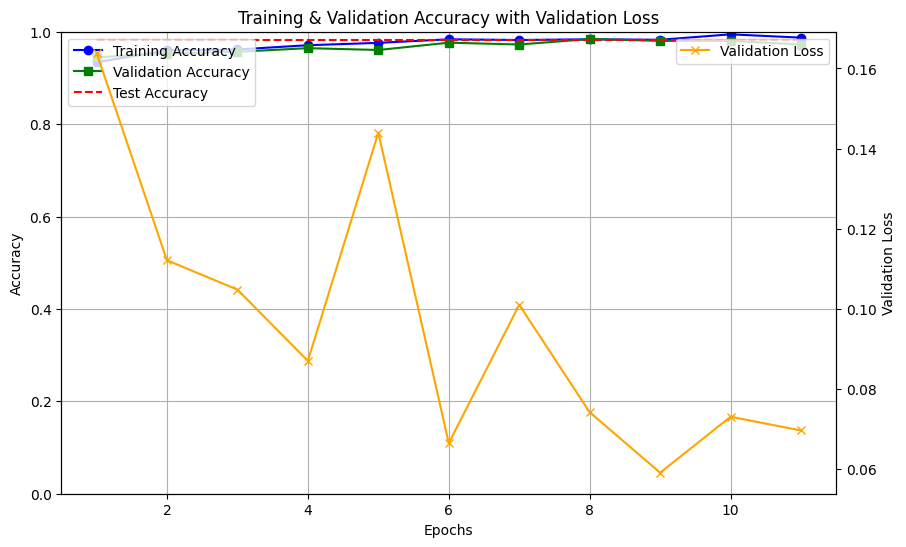

In [19]:
import matplotlib.pyplot as plt

# 1️⃣ Get metrics from history
train_acc = history_2.history['accuracy']
val_acc = history_2.history['val_accuracy']
val_loss = history_2.history['val_loss']

# Number of epochs actually run
epochs_ran = len(train_acc)
epochs = range(1, epochs_ran + 1)

# 2️⃣ Create figure and twin y-axis
fig, ax1 = plt.subplots(figsize=(10,6))

# Accuracy lines on left y-axis
ax1.plot(epochs, train_acc, label='Training Accuracy', marker='o', color='blue')
ax1.plot(epochs, val_acc, label='Validation Accuracy', marker='s', color='green')
ax1.hlines(test_acc, xmin=1, xmax=epochs_ran, colors='red', linestyles='dashed', label='Test Accuracy')

ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')
ax1.set_ylim(0, 1)
ax1.legend(loc='upper left')

# Loss line on right y-axis
ax2 = ax1.twinx()
ax2.plot(epochs, val_loss, label='Validation Loss', marker='x', color='orange')
ax2.set_ylabel('Validation Loss')
ax2.legend(loc='upper right')

# Title and grid
plt.title('Training & Validation Accuracy with Validation Loss')
ax1.grid(True)

plt.show()


**APPLICATION OF LOCAL INTERPRETABLE MODEL-AGNOSTIC EXPLANATIONS (LIME)**

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 10.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=be84f90e42cb0c629bfb6507a9857bac8937e0efa95f91bf5a8a88244f03b436
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime
Loading test data...
Found 106 images belonging to 4 classes.
Searching for image #0 of class 'diseased cotton leaf'...
Found image! Explaining image with True Class: diseased cotton leaf
Generating LIME explanation (this may take a moment)...


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 

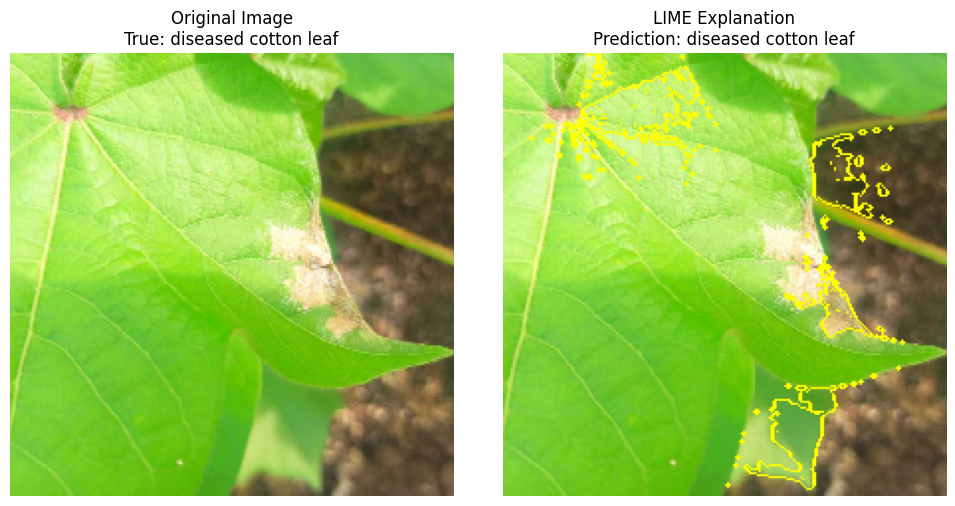

Explanation complete. Check the popup window for the plot.


In [20]:
!pip install lime
from lime import lime_image
from skimage.segmentation import mark_boundaries
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# Configuration
# -----------------------------
MODEL_PATH = 'model_efficientnet_final_optimized.h5'
TEST_DIR = r"/content/dataset/Cotton Disease/test"
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# -----------------------------


# -----------------------------
# Data Loading (For Visualization)
# -----------------------------
# We use a 'raw' generator for LIME to get interpretable images (0-255)
# This allows LIME's segmentation to work on actual pixels, not normalized values.
print("Loading test data...")
test_datagen_raw = ImageDataGenerator() # No preprocessing here!

test_generator_raw = test_datagen_raw.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True # Shuffle to get random images
)

# -----------------------------
# Prediction Function (The Bridge)
# -----------------------------
def predict_fn(images):
    """
    LIME passes 'images' as a numpy array of shape (batch, h, w, c).
    These images are in the range of the input provided to LIME (likely 0-255).
    We must preprocess them exactly as the model expects before predicting.
    """
    # 1. Ensure images are float32
    images = np.array(images, dtype=np.float32)

    # 2. Apply EfficientNet preprocessing
    # preprocess_input operates in-place or returns copy.
    # It handles the scaling (-1 to 1 or 0 to 255 depending on version).
    processed_images = preprocess_input(images.copy())

    # 3. Predict
    return model.predict(processed_images)

# -----------------------------
# Select an Image (Configuration)
# -----------------------------
# Change these values to select a specific image
TARGET_CLASS_NAME = 'diseased cotton leaf' # Options: diseased cotton leaf, diseased cotton plant, fresh cotton leaf, fresh cotton plant
TARGET_INDEX =  0   #  for the 1st image of that class found, 1 for the 2nd, etc.

print(f"Searching for image #{TARGET_INDEX} of class '{TARGET_CLASS_NAME}'...")

# Get class indices mapping
label_map = (test_generator_raw.class_indices)
label_map_inv = {v: k for k, v in label_map.items()}

if TARGET_CLASS_NAME not in label_map:
    print(f"Error: Class '{TARGET_CLASS_NAME}' not found. Available classes: {list(label_map.keys())}")
    exit()

target_class_idx = label_map[TARGET_CLASS_NAME]

# Scan the generator to find the target image
img_to_explain = None
true_label_idx = None
count = 0
found = False

# Reset generator to be sure
test_generator_raw.reset()

max_batches = len(test_generator_raw)
for i in range(max_batches):
    batch_images, batch_labels = next(test_generator_raw)

    # Iterate through batch
    for j in range(len(batch_images)):
        current_label_idx = np.argmax(batch_labels[j])

        if current_label_idx == target_class_idx:
            if count == TARGET_INDEX:
                img_to_explain = batch_images[j]
                true_label_idx = current_label_idx
                found = True
                break
            count += 1

    if found:
        break

if not found:
    print(f"Error: Could not find image #{TARGET_INDEX} of class '{TARGET_CLASS_NAME}'. Found {count} images total.")
    exit()

print(f"Found image! Explaining image with True Class: {label_map_inv[true_label_idx]}")

# -----------------------------
# Run LIME
# -----------------------------
print("Generating LIME explanation (this may take a moment)...")
explainer = lime_image.LimeImageExplainer()

explanation = explainer.explain_instance(
    image=img_to_explain.astype('double'), # LIME likes double/float
    classifier_fn=predict_fn,
    top_labels=5,
    hide_color=0,
    num_samples=1000 # Increase for better quality, decrease for speed
)

# -----------------------------
# Get Explanation for Top Class
# -----------------------------
top_pred_class = explanation.top_labels[0]
print(f"Top Predicted Class: {label_map_inv[top_pred_class]}")

# Get image and mask for the top class
# positive_only=True shows only superpixels that contribute POSITIVELY to the class
temp, mask = explanation.get_image_and_mask(
    top_pred_class,
    positive_only=True,
    num_features=5,
    hide_rest=False
)

# -----------------------------
# Visualize
# -----------------------------
plt.figure(figsize=(10, 5))

# Original Image
plt.subplot(1, 2, 1)
plt.imshow(img_to_explain.astype('uint8'))
plt.title(f"Original Image\nTrue: {label_map_inv[true_label_idx]}")
plt.axis('off')

# LIME Explanation
plt.subplot(1, 2, 2)
plt.imshow(mark_boundaries(temp.astype('uint8'), mask))
plt.title(f"LIME Explanation\nPrediction: {label_map_inv[top_pred_class]}")
plt.axis('off')

plt.tight_layout()
plt.show()

print("Explanation complete. Check the popup window for the plot.")
